### Figure as in Rogers cardiac fibroblast model

In [1]:
# =========================
# Per-input grid comparison
# =========================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import NetfluxODE_5_params
import matplotlib.patches as mpatches

[speciesNames, tau, ymax, y01, w, n, EC50] = NetfluxODE_5_params.loadParams()
bas=0.1
y0=bas*np.ones(len(y01))

from model_DOF_clustering_5 import objective_function, load_ko_and_expectation_data, wlen, family_id_vector, build_weight_vector, run_model_real

# [speciesNames, taux, ymaxx, y0x, wx, nx, EC50x] = NetfluxODE_5_params.loadParams()

ko_df, expectations_df = load_ko_and_expectation_data()

In [2]:
input_list = ['mechanical', 
              'infusionTGFB', 'AngII', 'IL6', 'FGF', 'PDGF','ET1', 'TNFa', 'IL1'
              ]
input_indices = {inp: speciesNames.index(inp) for inp in input_list if inp in speciesNames}

In [3]:


# --- configure your calibrated params here ---
# (Replace with your final values. b+p must be <= 1)
CAL_EC50 = 0.587798419904243
CAL_n    = 1.39569768592174
CAL_b    = 0.283201091629315
CAL_p    = 0.653814229335876

# CAL_EC50 = 0.568305675
# CAL_n    = 1.301942649
# CAL_b    = 0.291697537
# CAL_p    = 0.507453875 

# Family weights, length = n_families (5). Replace with your calibrated numbers.
CAL_W_FAMILIES = np.array([1.01915194, 1.09999999, 0.94966909, 1.1, 0.62873844])  # <-- EXAMPLE PLACEHOLDER

# Color map consistent with the paper figure
CAT2COLOR = {"increase": "#D94B4B", "no change": "#BFBFBF", "decrease": "#4B79D9"}

### functions to use

In [4]:
### FOR INPUT STIMULATION ###

def _label_from_delta(val, thr=0.05):
    if val >  thr:  return "increase"
    if val < -thr:  return "decrease"
    return "no change"

def compute_per_input_tables(EC50, n, b, p, w_families,
                             include_nodes="auto",
                             delta_threshold=0.05):
    """
    Returns:
      dict[input_name] -> DataFrame with columns ['experimental','model','match']
    """
    # Load experimental expectations & KO from your helper
    ko_df, expectations_df = load_ko_and_expectation_data()

    # Build EC50, n vectors
    EC50_vec = np.ones(wlen) * EC50
    n_vec    = np.ones(wlen) * n

    # Build full edge weights from family weights
    w_full_vec = build_weight_vector(w_families, family_id_vector)

    # Baseline input vector with b applied to all inputs
    baseline_input = y0.copy()
    for name, idx in input_indices.items():
        baseline_input[idx] = b

    baseline_ss = run_model_real(EC50_vec, n_vec, baseline_input,
                                 w_families, family_id_vector,
                                 w_override=w_full_vec)

    species_index = {s:i for i,s in enumerate(speciesNames)}

    # Which nodes to show?
    if include_nodes == "auto":
        # Only nodes that appear in the expectations sheet
        nodes = [node for node in expectations_df.index if node in species_index]
    else:
        nodes = [n for n in include_nodes if n in species_index]

    per_input = {}

    for inp in input_list:
        # forward (b+p) on this input
        perturbed = baseline_input.copy()
        perturbed[input_indices[inp]] = b + p

        ss = run_model_real(EC50_vec, n_vec, perturbed,
                            w_families, family_id_vector,
                            w_override=w_full_vec)

        delta = ss - baseline_ss

        rows = []
        for node in nodes:
            exp_val = expectations_df.loc[node, inp]
            if isinstance(exp_val, str):
                exp_lbl = exp_val.strip().lower()
            else:
                # Skip if expectation not categorical
                continue
            if exp_lbl not in ("increase", "decrease", "no change"):
                continue

            mdl_lbl = _label_from_delta(delta[species_index[node]], thr=delta_threshold)
            rows.append((node, exp_lbl, mdl_lbl, exp_lbl == mdl_lbl))

        df_inp = pd.DataFrame(rows, columns=["node","experimental","model","match"]).set_index("node")
        # Sort to keep "increase/no change/decrease" blocks together (optional)
        order_map = {"increase":0, "no change":1, "decrease":2}
        df_inp = df_inp.sort_values(by=["experimental","node"], key=lambda s: s.map(order_map).fillna(99))
        per_input[inp] = df_inp

    return per_input



def plot_per_input_grids(EC50, n, b, p, w_families,
                         include_nodes="auto",
                         delta_threshold=0.05,
                         ncols=3,
                         figsize=(18, 10),
                         title_prefix="Model vs. Experimental"):
    """
    Draws a small 2-column grid for each input: [Experimental | Model]
    Each row is a node; colors use Increase/No change/Decrease.
    ✓ marks rows where model matches experiment.
    """
    per_input = compute_per_input_tables(EC50, n, b, p, w_families,
                                         include_nodes, delta_threshold)

    inputs = [inp for inp in input_list if inp in per_input]
    nplots = len(inputs)
    nrows = int(np.ceil(nplots / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    for k, inp in enumerate(inputs):
        ax = axes[k // ncols, k % ncols]
        ax.set_visible(True)

        df = per_input[inp]
        nodes = df.index.tolist()

        # Make the x range narrower
        ax.set_xlim(0, 2)       # keep two columns
        ax.set_ylim(0, len(nodes))

        # Reduce column width
        col_width = 0.35   # << smaller width
        spacing   = 0.1    # gap between columns

        for i, node in enumerate(nodes):
            exp_lbl = df.loc[node, "experimental"]
            mdl_lbl = df.loc[node, "model"]

            # experimental rectangle
            rect_exp = mpatches.Rectangle((0.5 - col_width - spacing/2, i),
                                          col_width, 1,
                                          facecolor=CAT2COLOR[exp_lbl],
                                          edgecolor="k", linewidth=0.4)
            ax.add_patch(rect_exp)

            # model rectangle
            rect_mdl = mpatches.Rectangle((0.5 + spacing/2, i),
                                          col_width, 1,
                                          facecolor=CAT2COLOR[mdl_lbl],
                                          edgecolor="k", linewidth=0.4)
            ax.add_patch(rect_mdl)

            if df.loc[node, "match"]:
                ax.text(0.5, i+0.5, "✓", ha="center", va="center",
                        fontsize=9, fontweight="bold")

        # Cosmetics
        ax.set_title(inp, fontsize=10, pad=4)
        ax.set_xticks([0.5 - col_width/2, 0.5 + col_width/2])
        ax.set_xticklabels(["Exp", "Model"], fontsize=8)
        ax.set_yticks(np.arange(len(nodes)) + 0.5)
        ax.set_yticklabels(nodes, fontsize=7)
        ax.invert_yaxis()
        ax.tick_params(length=0)
        for spine in ["top","right","left","bottom"]:
            ax.spines[spine].set_visible(False)

    # Legend
    handles = [mpatches.Patch(facecolor=CAT2COLOR[k], edgecolor="k", label=k.title()) 
               for k in ["increase","no change","decrease"]]
    fig.legend(handles=handles, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(f"{title_prefix}", y=1.02, fontsize=13)
    fig.tight_layout()
    return fig




def plot_per_input_grids_equal_cells(EC50, n, b, p, w_families,
                                     include_nodes="auto",
                                     delta_threshold=0.05,
                                     ncols=3,
                                     fig_size=(18, 10),
                                     cell_h=0.028,     # height of ONE row (in figure fraction)
                                     col_w=0.26,       # width of ONE panel/column (figure fraction)
                                     xgap=0.04,        # horizontal gap between panels
                                     ygap=0.012,       # vertical gap between stacked panels
                                     title_prefix="Per-input prediction accuracy"):
    """
    Manually lays out axes so each table's row is the same pixel height,
    and the table height automatically scales with its number of rows.
    """
    per_input = compute_per_input_tables(EC50, n, b, p, w_families,
                                         include_nodes, delta_threshold)

    # order inputs predictably
    inputs = [inp for inp in input_list if inp in per_input]

    # assign inputs to columns (round-robin keeps columns balanced)
    cols = [[] for _ in range(ncols)]
    for i, inp in enumerate(inputs):
        cols[i % ncols].append(inp)

    # compute required total column heights in "row units"
    col_row_heights = [sum(len(per_input[inp]) for inp in col) for col in cols]

    # Figure: compute needed height so nothing overflows
    # total figure height fraction per column = rows*cell_h + gaps*(k-1)
    max_col_rows = max(col_row_heights) if col_row_heights else 1
    # Choose figure size so tallest column fits comfortably
    W, H = fig_size
    fig = plt.figure(figsize=(W, H))
    fig.suptitle(title_prefix, y=0.995, fontsize=13)

    # Compute left positions for each column
    total_w = ncols * col_w + (ncols - 1) * xgap
    x0 = (1.0 - total_w) / 2.0
    col_x = [x0 + j * (col_w + xgap) for j in range(ncols)]

    # For equal cell size ACROSS columns, we keep the same cell_h everywhere.
    # Bottom for each column starts high, then we stack downward.
    axes_made = []
    for j, col in enumerate(cols):
        # top of plotting area for this column
        top = 0.965
        # compute total height used by this column
        used_h = sum(len(per_input[inp]) * cell_h for inp in col) + max(len(col) - 1, 0) * ygap
        # center this column vertically
        bottom_start = top - used_h
        y_cursor = top

        for k, inp in enumerate(col):
            df = per_input[inp]
            nrows = len(df)
            if nrows == 0:
                continue
            panel_h = nrows * cell_h
            y_bottom = y_cursor - panel_h

            ax = fig.add_axes([col_x[j], y_bottom, col_w, panel_h])  # [left, bottom, width, height]
            axes_made.append(ax)

            # ---- draw the narrow two-column grid ----
            nodes = df.index.tolist()
            ax.set_xlim(0, 2)
            ax.set_ylim(0, nrows)

            col_width = 0.35
            spacing = 0.10
            for i_node, node in enumerate(nodes):
                exp_lbl = df.loc[node, "experimental"]
                mdl_lbl = df.loc[node, "model"]

                # experimental
                ax.add_patch(mpatches.Rectangle(
                    (0.5 - col_width - spacing/2, i_node),
                    col_width, 1, facecolor=CAT2COLOR[exp_lbl], edgecolor="k", linewidth=0.4))
                # model
                ax.add_patch(mpatches.Rectangle(
                    (0.5 + spacing/2, i_node),
                    col_width, 1, facecolor=CAT2COLOR[mdl_lbl], edgecolor="k", linewidth=0.4))

                if df.loc[node, "match"]:
                    ax.text(0.5, i_node + 0.5, "✓", ha="center", va="center",
                            fontsize=9, fontweight="bold")

            # cosmetics
            ax.set_xticks([0.5 - col_width/2, 0.5 + col_width/2])
            ax.set_xticklabels(["Exp", "Model"], fontsize=8)
            ax.set_yticks(np.arange(nrows) + 0.5)
            ax.set_yticklabels(nodes, fontsize=7)
            ax.invert_yaxis()
            ax.tick_params(length=0)
            for spine in ("top", "right", "left", "bottom"):
                ax.spines[spine].set_visible(False)

            # small title above this panel
            ax.text(0.5, -0.12, inp, ha="center", va="top", transform=ax.transAxes, fontsize=10)

            y_cursor = y_bottom - ygap  # next panel goes below

    # Legend (global)
    handles = [mpatches.Patch(facecolor=CAT2COLOR[k], edgecolor="k", label=k.title())
               for k in ("increase", "no change", "decrease")]
    fig.legend(handles=handles, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 0.005))
    return fig



def plot_per_input_grids_one_row_bottom_aligned(
    EC50, n, b, p, w_families,
    include_nodes="auto",
    delta_threshold=0.05,
    fig_size=(22, 5),
    # figure margins (fractions of figure)
    left=0.03, right=0.02, top=0.10, bottom=0.14,
    xgap=0.015,                    # gap between panels
    cell_h=None,                   # if None -> auto so tallest panel fills vertical space
    title_prefix="Per-input prediction accuracy"
    ):
    """One-row layout, all panels bottom-aligned, equal cell (row) height."""
    per_input = compute_per_input_tables(EC50, n, b, p, w_families,
                                         include_nodes, delta_threshold)

    inputs = [inp for inp in input_list if inp in per_input]
    ncols  = len(inputs)
    if ncols == 0:
        raise ValueError("No inputs to plot.")

    # Vertical sizing
    y_base = bottom
    y_top  = 1.0 - top
    max_rows = max(len(df) for df in per_input.values()) or 1
    # Square height: auto to use available vertical space
    if cell_h is None:
        cell_h = (y_top - y_base) / max_rows

    # Horizontal sizing
    avail_w = 1.0 - left - right - (ncols - 1) * xgap
    col_w   = avail_w / ncols
    xs = [left + i * (col_w + xgap) for i in range(ncols)]

    fig = plt.figure(figsize=fig_size)
    fig.suptitle(title_prefix, y=1 - top/2, fontsize=12)

    for i, inp in enumerate(inputs):
        df = per_input[inp]
        nrows = len(df)
        if nrows == 0:
            continue
        panel_h = nrows * cell_h  # == same cell size everywhere
        ax = fig.add_axes([xs[i], y_base, col_w, panel_h])  # bottom-aligned

        # Draw the two thin columns (Exp | Model)
        nodes = df.index.tolist()
        ax.set_xlim(0, 2)
        ax.set_ylim(0, nrows)

        col_width = 0.35
        spacing   = 0.10
        for r, node in enumerate(nodes):
            exp_lbl = df.loc[node, "experimental"]
            mdl_lbl = df.loc[node, "model"]

            ax.add_patch(mpatches.Rectangle((0.5 - col_width - spacing/2, r),
                                            col_width, 1,
                                            facecolor=CAT2COLOR[exp_lbl],
                                            edgecolor="k", linewidth=0.4))
            ax.add_patch(mpatches.Rectangle((0.5 + spacing/2, r),
                                            col_width, 1,
                                            facecolor=CAT2COLOR[mdl_lbl],
                                            edgecolor="k", linewidth=0.4))
            if df.loc[node, "match"]:
                ax.text(0.5, r+0.5, "✓", ha="center", va="center",
                        fontsize=8.5, fontweight="bold")

        # Cosmetics
        ax.set_xticks([0.5 - col_width/2, 0.5 + col_width/2])
        ax.set_xticklabels(["Exp", "Model"], fontsize=7)
        ax.set_yticks(np.arange(nrows) + 0.5)
        ax.set_yticklabels(nodes, fontsize=7)
        ax.invert_yaxis()
        ax.tick_params(length=0)
        for s in ("top", "right", "left", "bottom"):
            ax.spines[s].set_visible(False)
        # Panel title just above the bars
        ax.text(0.5, 1.02, inp, ha="center", va="bottom",
        transform=ax.get_xaxis_transform(), fontsize=9, clip_on=False)

    # Compact legend at the bottom center
    handles = [mpatches.Patch(facecolor=CAT2COLOR[k], edgecolor="k", label=k.title())
               for k in ("increase", "no change", "decrease")]
    fig.legend(handles=handles, ncol=3, loc="lower center",
               bbox_to_anchor=(0.5, bottom/2), fontsize=8)

    return fig


### FOR KO SIMULATIONS ###
def compute_per_KO_tables(EC50, n, b, w_families,
                          delta_threshold=0.02,
                          ko_subset=None):
    """
    Returns dict[ko_condition] -> DataFrame(index=node,
                columns=['experimental','model','match'])
    """
    ko_df, _expectations_df = load_ko_and_expectation_data()  # we only need ko_df

    # vectors/weights
    EC50_vec = np.full(wlen, EC50)
    n_vec    = np.full(wlen, n)
    w_full_vec = build_weight_vector(w_families, family_id_vector)

    # baseline: all inputs at b (no p here)
    baseline_input = y0.copy()
    for name, idx in input_indices.items():
        baseline_input[idx] = b
    baseline_ss = run_model_real(EC50_vec, n_vec, baseline_input,
                                 w_families, family_id_vector, w_override=w_full_vec)

    species_index = {s:i for i,s in enumerate(speciesNames)}

    # which KO columns to use
    all_kos = [c for c in ko_df.columns if c in speciesNames and c != 'specie']
    ko_cols = [k for k in (ko_subset or all_kos) if k in all_kos]

    per_KO = {}
    for ko_cond in ko_cols:
        # apply KO by zeroing ymax and y0 for that species
        ko_ymax = ymax.copy()
        ko_y0   = y0.copy()
        ko_ymax[speciesNames.index(ko_cond)] = 0.0
        ko_y0[speciesNames.index(ko_cond)]   = 0.0

        ko_ss = run_model_real(EC50_vec, n_vec, ko_y0,
                               w_families, family_id_vector,
                               ymax_override=ko_ymax, w_override=w_full_vec)

        delta = ko_ss - baseline_ss

        # rows to include = entries with a label in this KO column
        rows = []
        for _, row in ko_df.iterrows():
            node = row['specie']
            if node not in species_index:
                continue
            exp = row[ko_cond]
            if not isinstance(exp, str):
                continue
            exp_lbl = exp.strip().lower()
            if exp_lbl not in ("increase", "decrease", "no change"):
                continue

            d = delta[species_index[node]]
            if d >  delta_threshold: mdl_lbl = "increase"
            elif d < -delta_threshold: mdl_lbl = "decrease"
            else: mdl_lbl = "no change"

            rows.append((node, exp_lbl, mdl_lbl, exp_lbl == mdl_lbl))

        df_ko = pd.DataFrame(rows, columns=["node","experimental","model","match"]).set_index("node")
        # optional: keep similar sorting to inputs
        order_map = {"increase":0, "no change":1, "decrease":2}
        df_ko = df_ko.sort_values(by=["experimental","node"], key=lambda s: s.map(order_map).fillna(99))
        per_KO[ko_cond] = df_ko

    return per_KO


def plot_tables_one_row_bottom_aligned(tables_dict, title_prefix="",
                                       fig_size=(22,5),
                                       left=0.03, right=0.02, top=0.10, bottom=0.16,
                                       xgap=0.02, cell_h=None):
    """tables_dict: dict[name] -> DataFrame with ['experimental','model','match']"""
    names = list(tables_dict.keys())
    if not names:
        raise ValueError("No panels to plot.")

    # vertical sizing
    y_base = bottom; y_top = 1.0 - top
    max_rows = max(len(df) for df in tables_dict.values()) or 1
    if cell_h is None:
        cell_h = (y_top - y_base) / max_rows

    # horizontal sizing
    ncols = len(names)
    avail_w = 1.0 - left - right - (ncols - 1)*xgap
    col_w = avail_w / ncols
    xs = [left + i*(col_w + xgap) for i in range(ncols)]

    fig = plt.figure(figsize=fig_size)
    if title_prefix:
        fig.suptitle(title_prefix, y=1 - top/2, fontsize=12)

    for i, name in enumerate(names):
        df = tables_dict[name]
        nrows = len(df)
        if nrows == 0: 
            continue
        panel_h = nrows * cell_h
        ax = fig.add_axes([xs[i], y_base, col_w, panel_h])  # bottom-aligned

        nodes = df.index.tolist()
        ax.set_xlim(0, 2); ax.set_ylim(0, nrows)

        col_width = 0.35; spacing = 0.10
        for r, node in enumerate(nodes):
            exp_lbl = df.loc[node, "experimental"]
            mdl_lbl = df.loc[node, "model"]
            ax.add_patch(mpatches.Rectangle((0.5 - col_width - spacing/2, r),
                        col_width, 1, facecolor=CAT2COLOR[exp_lbl], edgecolor="k", linewidth=0.4))
            ax.add_patch(mpatches.Rectangle((0.5 + spacing/2, r),
                        col_width, 1, facecolor=CAT2COLOR[mdl_lbl], edgecolor="k", linewidth=0.4))
            if df.loc[node, "match"]:
                ax.text(0.5, r+0.5, "✓", ha="center", va="center", fontsize=8.5, fontweight="bold")

        ax.set_xticks([0.5 - col_width/2, 0.5 + col_width/2])
        ax.set_xticklabels(["Exp", "Model"], fontsize=7)
        ax.set_yticks(np.arange(nrows) + 0.5)
        ax.set_yticklabels(nodes, fontsize=7)
        ax.invert_yaxis(); ax.tick_params(length=0)
        for s in ("top","right","left","bottom"): ax.spines[s].set_visible(False)
        # center title over the bars
        ax.text(0.5, 1.02, name, ha="center", va="bottom",
                transform=ax.get_xaxis_transform(), fontsize=9, clip_on=False)

    handles = [mpatches.Patch(facecolor=CAT2COLOR[k], edgecolor="k", label=k.title())
               for k in ("increase","no change","decrease")]
    fig.legend(handles=handles, ncol=3, loc="lower center",
               bbox_to_anchor=(0.5, bottom/2), fontsize=8)
    return fig


##### Run here the function to use to plot the figure for INPUT STIMULATION dataset.

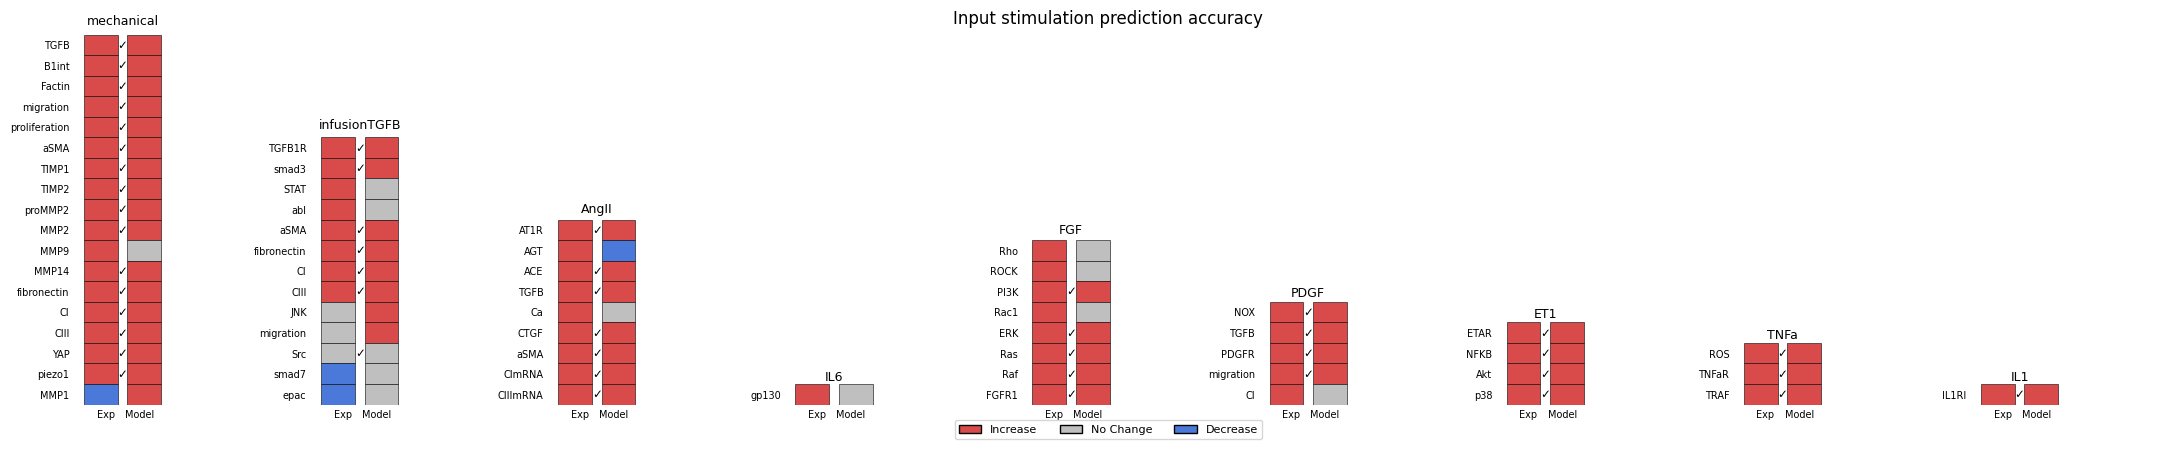

In [5]:
# =========================
# Run it
# =========================
# If you want to preselect a subset of nodes, pass include_nodes=[...]
# fig = plot_per_input_grids(CAL_EC50, CAL_n, CAL_b, CAL_p, CAL_W_FAMILIES,
#                            include_nodes="auto",
#                            delta_threshold=0.05,
#                            ncols=3, figsize=(20, 12),
#                            title_prefix="Per-input prediction accuracy")

# fig = plot_per_input_grids_equal_cells(   ###GOOD TO TRY WITH MORE COLUMNS THAN 1
#     CAL_EC50, CAL_n, CAL_b, CAL_p, CAL_W_FAMILIES,
#     include_nodes="auto",
#     delta_threshold=0.05,
#     ncols=9, fig_size=(24, 18),
#     cell_h=0.010,   # tweak this to make squares bigger/smaller
#     col_w=0.07,     # tweak to make panels narrower/wider
#     xgap=0.05, ygap=0.02,
#     title_prefix="Per-input prediction accuracy"
# )

fig = plot_per_input_grids_one_row_bottom_aligned(
    CAL_EC50, CAL_n, CAL_b, CAL_p, CAL_W_FAMILIES,
    include_nodes="auto",
    delta_threshold=0.05,
    fig_size=(22, 5),         # one-row canvas
    xgap=0.02,                # tweak to pack/unpack horizontally
    cell_h=None,              # auto: tallest panel fills vertical space
    left=0.03, right=0.02, top=0.10, bottom=0.16,
    title_prefix="Input stimulation prediction accuracy"
)

# To save:
fig.savefig("input_stimulation_grids.png", dpi=300, bbox_inches="tight")


##### Run here the function to use to plot the figure for KO dataset.

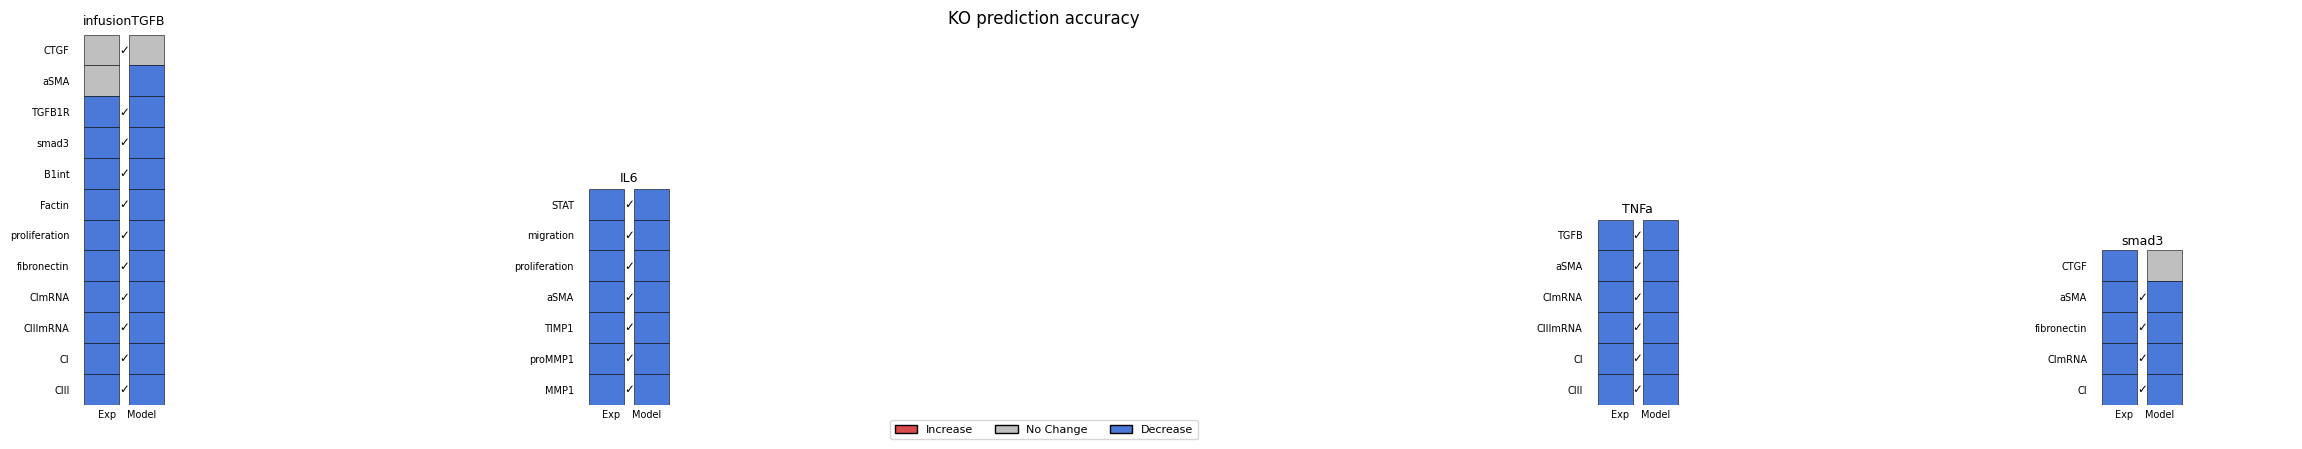

In [6]:
# Build the KO tables (p not used here)
per_KO = compute_per_KO_tables(CAL_EC50, CAL_n, CAL_b, CAL_W_FAMILIES,
                               delta_threshold=0.02,
                               ko_subset=None)  # or pass a list like ["ERK","PI3K",...]

fig = plot_tables_one_row_bottom_aligned(
    per_KO,
    title_prefix="KO prediction accuracy",
    fig_size=(26, 5),   # widen if many KOs
    xgap=0.02, cell_h=None  # auto cell size so tallest panel sets the height
)
fig.savefig("ko_prediction_accuracy.png", dpi=300, bbox_inches="tight")


In [7]:
per_inp = compute_per_input_tables(CAL_EC50, CAL_n, CAL_b, CAL_p, CAL_W_FAMILIES,
                                   include_nodes="auto", delta_threshold=0.05)
per_ko  = compute_per_KO_tables(CAL_EC50, CAL_n, CAL_b, CAL_W_FAMILIES,
                                delta_threshold=0.02, ko_subset=None)

stim_match = sum(df["match"].sum() for df in per_inp.values())
stim_total = sum(len(df)            for df in per_inp.values())
ko_match   = sum(df["match"].sum() for df in per_ko.values())
ko_total   = sum(len(df)            for df in per_ko.values())

print(f"Stim: {stim_match}/{stim_total}  = {100*stim_match/stim_total:.1f}% correct")
print(f"KO:   {ko_match}/{ko_total}      = {100*ko_match/ko_total:.1f}% correct")
print(f"Implied loss (% mismatches summed) = {(100 - 100*stim_match/stim_total) + (100 - 100*ko_match/ko_total):.2f}")

Stim: 47/62  = 75.8% correct
KO:   28/30      = 93.3% correct
Implied loss (% mismatches summed) = 30.86


## Combined layout: single Figure 2-style panel (added after revision)

Generates the single figure that matches the paper's Figure 2: one subplot per input stimulus or KO condition, each showing side-by-side Experiment / Model columns with Red / Gray / Blue boxes for Increase / No change / Decrease, and a check mark where they agree. Saves as `Figure2_combined_layout.png`.

Starting point is `plot_combined_calibration_layout_refined` from `Fig_modelVSexp.ipynb`. Two refinements applied here:
- Harmonized ternary threshold at 0.05 for both input stimulation and KO scoring (reviewer #1).
- Output filename changed to `Figure2_combined_layout.png` so it does not overwrite the earlier `combined_calibration_layout_refined.png`.

Uses the scalars already defined in the notebook above (`CAL_EC50`, `CAL_n`, `CAL_b`, `CAL_p`, `CAL_W_FAMILIES`). If those are the pre-revision Set B values, update them to the post-revision best before running:
```
CAL_EC50 = 0.630717
CAL_n    = 1.508259
CAL_b    = 0.473192
CAL_p    = 0.205622
CAL_W_FAMILIES = np.array([1.0, 1.0, 1.0, 1.0, 1.0])
```

In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle

# ============================================================
# COLORS
# ============================================================
STATE_COLORS = {
    "increase": "#d95b59",
    "no change": "#c9c9c9",
    "decrease": "#4f7fd8"
}

# ============================================================
# DRAW ONE PANEL
# ============================================================
def _draw_single_table_panel(
    ax,
    df,
    panel_title,
    *,
    cell_w=0.95,
    agree_w=0.36,
    row_fs=10,
    title_fs=13,
    xtick_fs=9,
    check_fs=11,
    edge_lw=0.6,
    edge_color="#4f4f4f",
    title_pad=0.45,
):
    labels = list(df.index)
    nrows = len(labels)

    x_exp = 0.0
    x_agr = x_exp + cell_w
    x_mod = x_agr + agree_w
    total_w = 2 * cell_w + agree_w

    ax.set_xlim(-1.55, total_w + 0.15)
    ax.set_ylim(-0.9, nrows + 1.0)
    ax.invert_yaxis()

    for i, label in enumerate(labels):
        y = i
        exp_state = df.loc[label, "experimental"]
        mod_state = df.loc[label, "model"]
        is_match  = bool(df.loc[label, "match"])

        ax.text(-0.12, y + 0.5, label,
                ha="right", va="center", fontsize=row_fs)

        ax.add_patch(Rectangle(
            (x_exp, y), cell_w, 1.0,
            facecolor=STATE_COLORS[exp_state],
            edgecolor=edge_color, linewidth=edge_lw
        ))

        ax.add_patch(Rectangle(
            (x_agr, y), agree_w, 1.0,
            facecolor="white",
            edgecolor=edge_color, linewidth=edge_lw
        ))

        if is_match:
            ax.text(x_agr + agree_w/2, y + 0.5, "✓",
                    ha="center", va="center",
                    fontsize=check_fs, fontweight="bold")

        ax.add_patch(Rectangle(
            (x_mod, y), cell_w, 1.0,
            facecolor=STATE_COLORS[mod_state],
            edgecolor=edge_color, linewidth=edge_lw
        ))

    ax.text(x_exp + cell_w/2, nrows + 0.25, "Exp",
            ha="center", va="center", fontsize=xtick_fs)
    ax.text(x_mod + cell_w/2, nrows + 0.25, "Model",
            ha="center", va="center", fontsize=xtick_fs)

    ax.text(total_w/2, -title_pad, panel_title,
            ha="center", va="center",
            fontsize=title_fs, fontweight="bold")

    ax.axis("off")


# ============================================================
# IMPROVED MANUAL COMPOSITE LAYOUT
# ============================================================
def plot_combined_calibration_layout_refined(
    EC50, n, b, p, w_families,
    input_delta_threshold=0.05,
    ko_delta_threshold=0.02,
    include_nodes="auto",
    ko_subset=None,
    fig_size=(16, 10),
    savepath=None,
    dpi=300,
):
    # --------------------------------------------------------
    # Tables
    # --------------------------------------------------------
    per_input = compute_per_input_tables(
        EC50, n, b, p, w_families,
        include_nodes=include_nodes,
        delta_threshold=input_delta_threshold
    )

    per_KO = compute_per_KO_tables(
        EC50, n, b, w_families,
        delta_threshold=ko_delta_threshold,
        ko_subset=ko_subset
    )

    fig = plt.figure(figsize=fig_size, facecolor="white")

    # --------------------------------------------------------
    # Small IL6 panel = gp130 row from input IL6
    # --------------------------------------------------------
    def get_il6_input_df():
        df_il6 = per_input["IL6"]
        if "gp130" in df_il6.index:
            return df_il6.loc[["gp130"]].copy()
        return df_il6.iloc[[0]].copy()

    # --------------------------------------------------------
    # REFINED LAYOUT
    # tuned to better match your manual composition
    # --------------------------------------------------------
    layout = {
        # top row
        ("input", "mechanical"):   [0.05, 0.54, 0.10, 0.39],

        ("input", "infusionTGFB"): [0.20, 0.54, 0.10, 0.26],
        ("ko",    "infusionTGFB"): [0.34, 0.54, 0.11, 0.39],

        ("input", "AngII"):        [0.52, 0.54, 0.085, 0.22],

        # IL6 arrangement: input-stim panel (gp130) on top, KO panel below
        # (previous layout overlapped both panels in y, producing "IL6IL6")
        ("input", "IL6_input"):    [0.665, 0.84, 0.055, 0.075],
        ("ko",    "IL6"):          [0.63,  0.54, 0.095, 0.25],

        ("input", "IL1"):          [0.78, 0.54, 0.055, 0.075],

        # bottom row
        ("input", "FGF"):          [0.05, 0.22, 0.085, 0.22],
        ("input", "PDGF"):         [0.18, 0.22, 0.068, 0.15],
        ("input", "ET1"):          [0.285, 0.22, 0.060, 0.12],
        ("input", "TNFa"):         [0.42, 0.22, 0.060, 0.095],

        ("ko",    "TNFa"):         [0.58, 0.22, 0.095, 0.24],
        ("ko",    "smad3"):        [0.75, 0.22, 0.095, 0.20],
    }

    title_map = {
        ("input", "mechanical"): "mechanical",
        ("input", "infusionTGFB"): "infusionTGFB",
        ("ko",    "infusionTGFB"): "infusionTGFB",
        ("input", "AngII"): "AngII",
        ("input", "IL6_input"): "IL6",
        ("ko",    "IL6"): "IL6",
        ("input", "IL1"): "IL1",
        ("input", "FGF"): "FGF",
        ("input", "PDGF"): "PDGF",
        ("input", "ET1"): "ET1",
        ("input", "TNFa"): "TNFa",
        ("ko",    "TNFa"): "TNFa",
        ("ko",    "smad3"): "smad3",
    }

    # --------------------------------------------------------
    # Draw panels
    # --------------------------------------------------------
    for key, pos in layout.items():
        kind, name = key
        ax = fig.add_axes(pos)

        if kind == "input":
            if name == "IL6_input":
                df = get_il6_input_df()
            else:
                if name not in per_input:
                    continue
                df = per_input[name]
        else:
            if name not in per_KO:
                continue
            df = per_KO[name]

        _draw_single_table_panel(
            ax,
            df,
            title_map[key],
            row_fs=9.5,
            title_fs=12.5,
            xtick_fs=8.5,
            check_fs=10.5,
            edge_lw=0.55,
            edge_color="#4d4d4d",
            title_pad=0.42
        )

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------
    handles = [
        mpatches.Patch(facecolor=STATE_COLORS["increase"], edgecolor="black", label="Increase"),
        mpatches.Patch(facecolor=STATE_COLORS["no change"], edgecolor="black", label="No change"),
        mpatches.Patch(facecolor=STATE_COLORS["decrease"], edgecolor="black", label="Decrease"),
        mpatches.Patch(facecolor="white", edgecolor="white", label="✓ Agreement"),
    ]

    fig.legend(
        handles=handles,
        ncol=4,
        frameon=False,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.065),
        fontsize=12,
        handlelength=1.8,
        handletextpad=0.45,
        columnspacing=1.5
    )

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight", facecolor="white")

    return fig

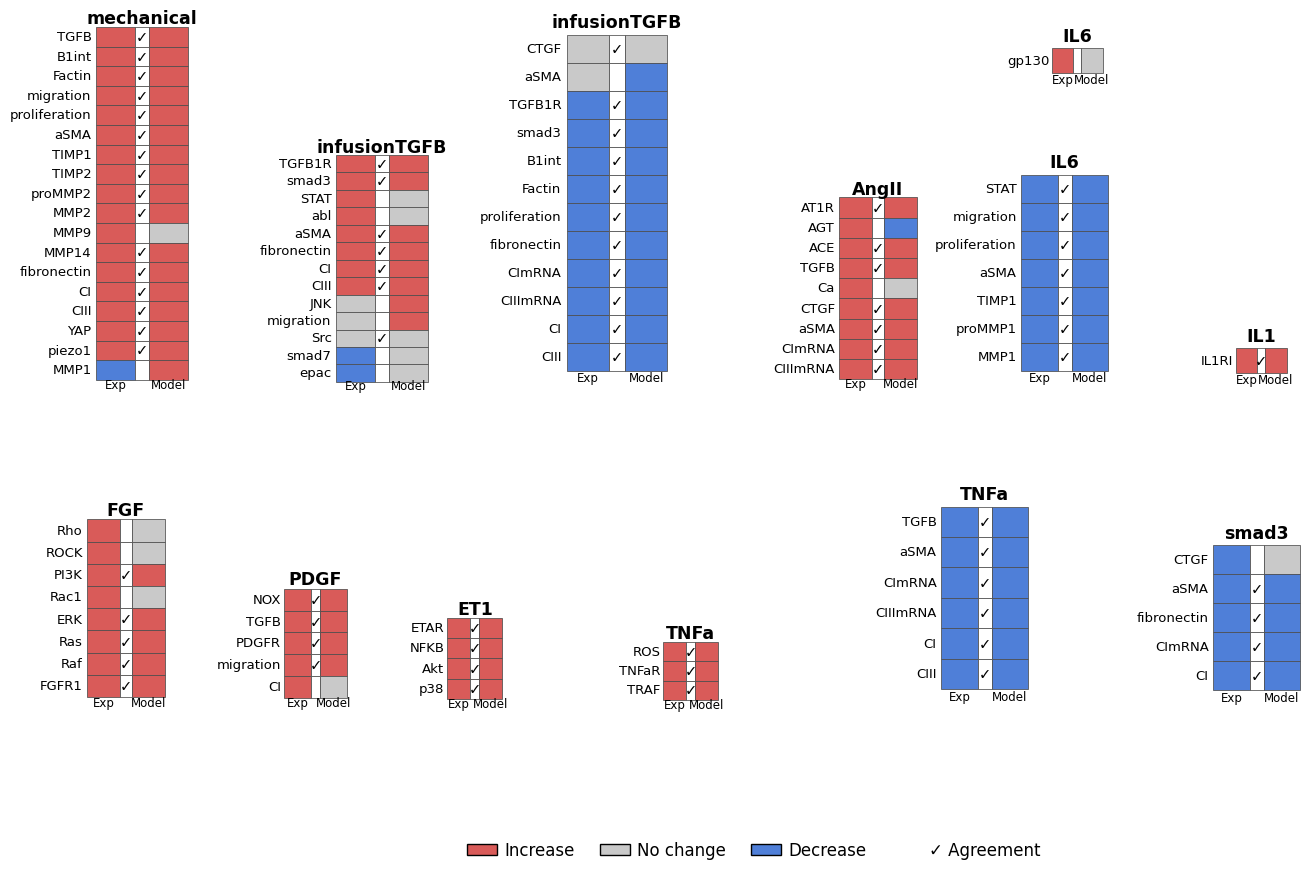

In [9]:
fig = plot_combined_calibration_layout_refined(
    CAL_EC50, CAL_n, CAL_b, CAL_p, CAL_W_FAMILIES,
    input_delta_threshold=0.05,
    ko_delta_threshold=0.02,  # matches standalone KO cell / submission
    include_nodes="auto",
    ko_subset=None,
    fig_size=(16, 10),
    savepath="combined_calibration_layout_submission.png",
    dpi=600,
)

plt.show()